In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler



In [2]:
df=pd.read_csv("../dataset/Indian_Student_Placement_Dataset_2025.csv")
df

,student_id,gender,age,degree,branch,cgpa,backlogs,internships,certifications,coding_skills,communication_skills,aptitude_score,projects,placed,company_type,package_lpa
0,1,Male,20,BE,Mechanical,8.40,2,2,2,1,3,69,0,0,NaN,0.00
1,2,Female,20,BTech,Electrical,8.60,2,0,5,1,9,81,4,0,NaN,0.00
2,3,Male,22,BCA,Electrical,6.62,3,0,1,1,7,50,1,0,NaN,0.00
3,4,Male,24,BCA,DS,8.01,0,0,4,4,7,47,4,0,NaN,0.00
4,5,Male,24,BCA,Electrical,9.12,2,1,2,4,4,77,4,0,NaN,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,11996,Female,20,BCA,CS,7.19,2,0,3,7,7,86,2,1,Startup,9.37
11996,11997,Female,24,BTech,IT,6.09,3,1,5,10,7,52,2,0,NaN,0.00
11997,11998,Male,22,BTech,Mechanical,8.02,0,0,0,8,5,44,0,0,NaN,0.00
11998,11999,Male,20,BE,CS,6.40,0,0,5,9,3,47,3,0,NaN,0.00


In [3]:
df.isnull().sum()
df["company_type"]=df["company_type"].fillna(df["company_type"].mode()[0])
df.isnull().sum()
df.head()
#df.duplicated()

,student_id,gender,age,degree,branch,cgpa,backlogs,internships,certifications,coding_skills,communication_skills,aptitude_score,projects,placed,company_type,package_lpa
0,1,Male,20,BE,Mechanical,8.40,2,2,2,1,3,69,0,0,Product,0.0
1,2,Female,20,BTech,Electrical,8.60,2,0,5,1,9,81,4,0,Product,0.0
2,3,Male,22,BCA,Electrical,6.62,3,0,1,1,7,50,1,0,Product,0.0
3,4,Male,24,BCA,DS,8.01,0,0,4,4,7,47,4,0,Product,0.0
4,5,Male,24,BCA,Electrical,9.12,2,1,2,4,4,77,4,0,Product,0.0


In [4]:
x=df.drop(columns=['student_id','company_type','package_lpa','placed'])
y=df['placed']
print(x.head())

   gender  age degree      branch  cgpa  backlogs  internships  \
0    Male   20     BE  Mechanical  8.40         2            2   
1  Female   20  BTech  Electrical  8.60         2            0   
2    Male   22    BCA  Electrical  6.62         3            0   
3    Male   24    BCA          DS  8.01         0            0   
4    Male   24    BCA  Electrical  9.12         2            1   

   certifications  coding_skills  communication_skills  aptitude_score  \
0               2              1                     3              69   
1               5              1                     9              81   
2               1              1                     7              50   
3               4              4                     7              47   
4               2              4                     4              77   

   projects  
0         0  
1         4  
2         1  
3         4  
4         4  


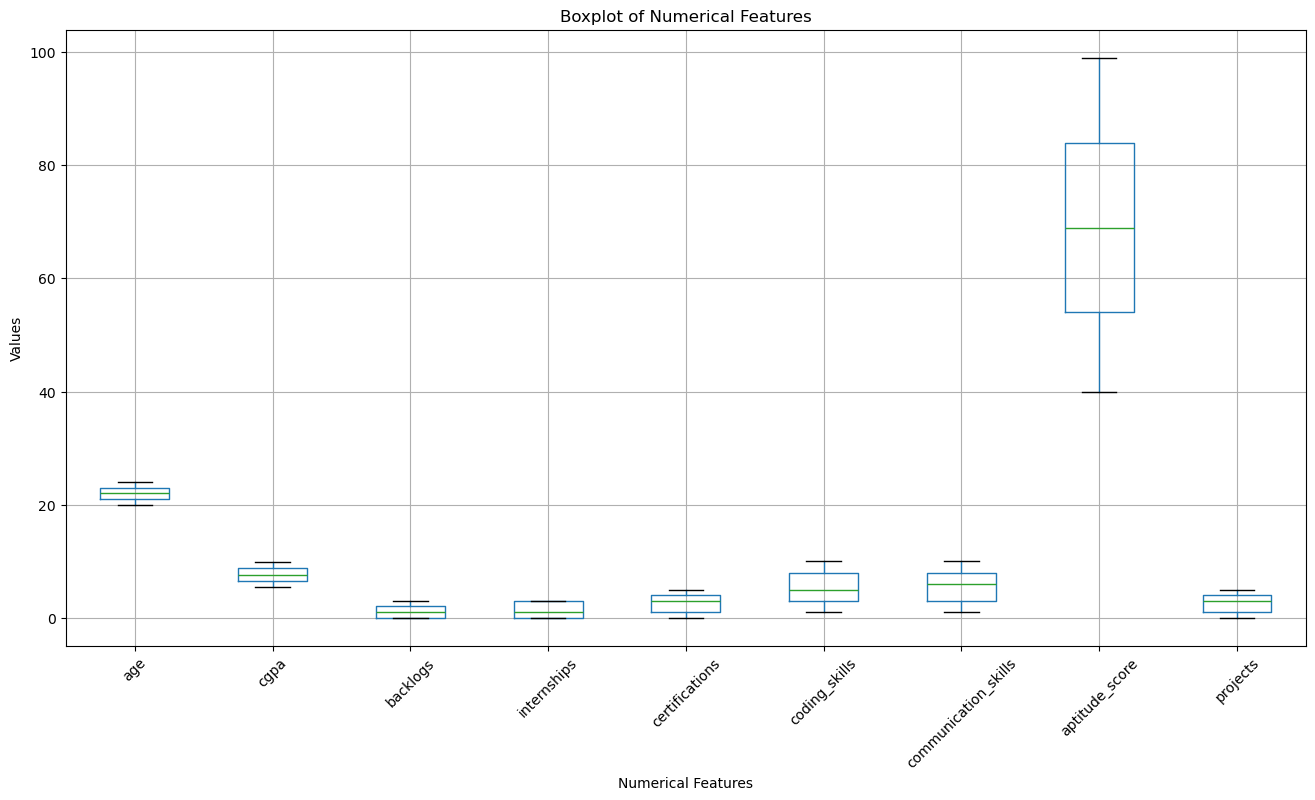

In [5]:
numeric_cols = [
    'age',
    'cgpa',
    'backlogs',
    'internships',
    'certifications',
    'coding_skills',
    'communication_skills',
    'aptitude_score',
    'projects'     
]
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))

df[numeric_cols].boxplot()

plt.title("Boxplot of Numerical Features")
plt.xlabel("Numerical Features")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [6]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(9600, 12)
(2400, 12)
(9600,)
(2400,)


In [7]:
categorical_cols = ['gender', 'degree', 'branch']
numerical_cols = [
    'cgpa', 'backlogs','age', 'internships', 'certifications',
    'coding_skills', 'communication_skills', 'aptitude_score', 'projects'
]
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ]
)

x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

joblib.dump(preprocessor, '../models/scaler_pipeline.pkl')
print("Preprocessor saved successfully as '../models/scaler_pipeline.pkl!")

Preprocessor saved successfully as '../models/scaler_pipeline.pkl!


In [8]:
rf_model=RandomForestClassifier()
rf_model.fit(x_train_processed,y_train)
rf_pred=rf_model.predict(x_test_processed)
accuracy=accuracy_score(rf_pred,y_test)
print("random forest accuracy:",accuracy)
lr_model=LogisticRegression()
lr_model.fit(x_train_processed,y_train)
lr_pred=lr_model.predict(x_test_processed)
accuracy=accuracy_score(lr_pred,y_test)
print("logistic regression accuracy:",accuracy)
joblib.dump(rf_model,'../models/rf_model.pkl')
print("Model saved sucessfully as 'rf_model.pkl'!")


random forest accuracy: 1.0
logistic regression accuracy: 0.8458333333333333
Model saved sucessfully as 'rf_model.pkl'!
